# Support Vector Machines Classifier (SVC) as a baseline

In [15]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.base import clone
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (f1_score, precision_score, recall_score, balanced_accuracy_score)

import warnings
warnings.filterwarnings("ignore")



## <font color="orange"> Data Loading <font>

In [16]:
path = "../data/extraction/meta_mean_std_mfcc.csv"
df = pd.read_csv(path)
df.head()

,file,duration,transcription,speaker,gender,age,emotion,emotion.confidence,emotion.naturalness,mfcc_mean_1,...,delta_std_11,delta_std_12,delta_std_13,delta_std_14,delta_std_15,delta_std_16,delta_std_17,delta_std_18,delta_std_19,delta_std_20
0,/home/anh-dung-le/audb/emodb/2.0.0/d3b62a9b/wa...,0 days 00:00:01.898250000,a01,3,male,31,happiness,0.90,0.75,-321.306000,...,1.550109,1.159719,1.152341,1.352440,1.158564,0.969121,0.849382,0.844728,0.807716,0.814517
1,/home/anh-dung-le/audb/emodb/2.0.0/d3b62a9b/wa...,0 days 00:00:01.611250000,a01,3,male,31,neutral,1.00,0.95,-322.462976,...,1.518675,1.496530,1.123413,0.970171,1.484902,0.694235,1.298124,0.883971,1.067266,0.582751
2,/home/anh-dung-le/audb/emodb/2.0.0/d3b62a9b/wa...,0 days 00:00:01.877812500,a01,3,male,31,anger,0.95,0.90,-300.835980,...,1.580734,1.366172,1.259567,1.291065,1.324476,1.249770,1.202631,0.821312,0.877034,0.835950
3,/home/anh-dung-le/audb/emodb/2.0.0/d3b62a9b/wa...,0 days 00:00:02.006250000,a02,3,male,31,happiness,0.85,0.60,-305.514536,...,1.392360,1.240131,1.051630,1.184306,1.127038,1.075541,1.038948,0.906845,1.230960,0.893336
4,/home/anh-dung-le/audb/emodb/2.0.0/d3b62a9b/wa...,0 days 00:00:01.439812500,a02,3,male,31,neutral,1.00,0.95,-305.962147,...,1.247700,1.187863,1.010545,0.838740,1.183253,0.725776,0.922650,0.753378,0.695016,0.617318


## <font color="orange"> Feature Selection and Split <font>

In [17]:
# keep mfcc-related cols
stat_cols = [c for c in df.columns if c.startswith(("mfcc_mean_", "mfcc_std_", "delta_mean_", "delta_std_"))]
X = df[stat_cols].copy()

# metadata cols also
X["gender"] = (df["gender"] == "male").astype(int)
X["age"] = df["age"].astype(float)

In [18]:
# show first few rows
X.head()

,mfcc_mean_1,mfcc_mean_2,mfcc_mean_3,mfcc_mean_4,mfcc_mean_5,mfcc_mean_6,mfcc_mean_7,mfcc_mean_8,mfcc_mean_9,mfcc_mean_10,...,delta_std_13,delta_std_14,delta_std_15,delta_std_16,delta_std_17,delta_std_18,delta_std_19,delta_std_20,gender,age
0,-321.306000,9.669931,-41.315235,33.774169,-29.929212,19.328474,-23.542137,4.895682,-9.851787,1.101428,...,1.152341,1.352440,1.158564,0.969121,0.849382,0.844728,0.807716,0.814517,1,31.0
1,-322.462976,30.320147,-42.097983,31.981602,-25.557349,17.140117,-19.730400,7.482372,-11.211044,3.936103,...,1.123413,0.970171,1.484902,0.694235,1.298124,0.883971,1.067266,0.582751,1,31.0
2,-300.835980,0.977344,-56.865403,25.825857,-30.137908,15.278820,-21.376164,4.381688,-14.007864,0.172622,...,1.259567,1.291065,1.324476,1.249770,1.202631,0.821312,0.877034,0.835950,1,31.0
3,-305.514536,-0.129116,-44.507566,29.120147,-33.680070,19.283297,-26.528275,5.708885,-16.288680,-1.401260,...,1.051630,1.184306,1.127038,1.075541,1.038948,0.906845,1.230960,0.893336,1,31.0
4,-305.962147,26.578828,-36.236041,37.371035,-22.652406,16.741552,-20.569939,6.261011,-12.960843,1.979905,...,1.010545,0.838740,1.183253,0.725776,0.922650,0.753378,0.695016,0.617318,1,31.0


In [19]:
# target: emotion labels
# encoding
le = LabelEncoder()
y = le.fit_transform(df["emotion"])          # XGBoost needs integer labels


In [20]:
# get sample weights from confidence
w = df["emotion.confidence"].astype(float)
w = (w / w.mean()).values

In [21]:
# consider 4 configurations
configs = {
    "acoustic only":  stat_cols,                     # only mfcc features
    "acoustic_w_gender_age": stat_cols + ["gender", "age"], # add both
}


In [22]:
# split: leave one speaker out 
groups = df["speaker"].values
logo = LeaveOneGroupOut()


## <font color="orange"> Modelling: no tune <font>

In [23]:
# definition
model_wo_PCA = Pipeline([
    ("scale", StandardScaler()),
    ("svc", SVC(
        kernel="rbf",
        C=1.5,
        gamma="scale",
        decision_function_shape="ovr", 
        random_state=42,
    )),
])

# definition
model_w_PCA = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("svc", SVC(
        kernel="rbf",
        C=1.5,
        gamma="scale",
        decision_function_shape="ovr",        
        random_state=42,
    )),
])

In [24]:
def train_model(model, C, gamma):
    rows = []
    for name, cols in configs.items():
        m = clone(model).set_params(svc__C=C, svc__gamma=gamma)   # fresh model per config, new C, new gamma
        balanced_acc, f1 = [], []
        balanced_acc_tr, f1_tr = [], []
        for tr, te in logo.split(X, y, groups):
            cw = compute_sample_weight("balanced", y[tr])
            w_comb = w[tr] * cw
            w_comb = w_comb / w_comb.mean()

            m.fit(X.iloc[tr][cols], y[tr], svc__sample_weight=w_comb)
            y_pred = m.predict(X.iloc[te][cols])
            y_pred_train = m.predict(X.iloc[tr][cols])

            balanced_acc.append(balanced_accuracy_score(y[te], y_pred))
            #pre.append(precision_score(y[te], y_pred, average="macro", zero_division=0))
            #rec.append(recall_score(y[te], y_pred, average="macro", zero_division=0))
            f1.append(f1_score(y[te], y_pred, average="macro", zero_division=0))
            balanced_acc_tr.append(balanced_accuracy_score(y[tr], y_pred_train))
            #pre_tr.append(precision_score(y[tr], y_pred_train, average="macro", zero_division=0))
            #rec_tr.append(recall_score(y[tr], y_pred_train, average="macro", zero_division=0))
            f1_tr.append(f1_score(y[tr], y_pred_train, average="macro", zero_division=0))

        rows.append({
            "config": name, "C": C, "gamma": gamma,
            "test_balanced_acc": np.mean(balanced_acc),  "test_balanced_acc_std": np.std(balanced_acc),
            "train_balanced_acc": np.mean(balanced_acc_tr), "train_balanced_acc_std": np.std(balanced_acc_tr),
            "test_f1": np.mean(f1),    "test_f1_std": np.std(f1),
            "train_f1": np.mean(f1_tr), "train_f1_std": np.std(f1_tr),
        })
    return rows


In [25]:
def heatmap(ax, d, value, title, cmap="viridis"):
    p = d.pivot(index="C", columns="gamma", values=value).sort_index().sort_index(axis=1)
    im = ax.imshow(p.values, origin="lower", aspect="auto", cmap=cmap)
    ax.set_xticks(range(len(p.columns))); ax.set_xticklabels([f"{g:.1e}" for g in p.columns], rotation=45)
    ax.set_yticks(range(len(p.index)));   ax.set_yticklabels([f"{c:.3g}" for c in p.index])
    ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title(title)
    for i in range(p.shape[0]):
        for j in range(p.shape[1]):
            ax.text(j, i, f"{p.values[i, j]:.2f}", ha="center", va="center", color="w", fontsize=7)
    plt.colorbar(im, ax=ax)

In [26]:
# sweep C and gamma
Cs = np.logspace(-1, 2, 12)        
gammas = np.logspace(-4, -1, 12) 

C=0.1, gamma=0.0001
C=0.1, gamma=0.000187382
C=0.1, gamma=0.000351119
C=0.1, gamma=0.000657933
C=0.1, gamma=0.00123285
C=0.1, gamma=0.00231013
C=0.1, gamma=0.00432876
C=0.1, gamma=0.00811131
C=0.1, gamma=0.0151991
C=0.1, gamma=0.0284804
C=0.1, gamma=0.053367
C=0.1, gamma=0.1
C=0.187382, gamma=0.0001
C=0.187382, gamma=0.000187382
C=0.187382, gamma=0.000351119
C=0.187382, gamma=0.000657933
C=0.187382, gamma=0.00123285
C=0.187382, gamma=0.00231013
C=0.187382, gamma=0.00432876
C=0.187382, gamma=0.00811131
C=0.187382, gamma=0.0151991
C=0.187382, gamma=0.0284804
C=0.187382, gamma=0.053367
C=0.187382, gamma=0.1
C=0.351119, gamma=0.0001
C=0.351119, gamma=0.000187382
C=0.351119, gamma=0.000351119
C=0.351119, gamma=0.000657933
C=0.351119, gamma=0.00123285
C=0.351119, gamma=0.00231013
C=0.351119, gamma=0.00432876
C=0.351119, gamma=0.00811131
C=0.351119, gamma=0.0151991
C=0.351119, gamma=0.0284804
C=0.351119, gamma=0.053367
C=0.351119, gamma=0.1
C=0.657933, gamma=0.0001
C=0.657933, gamma=0.0001873

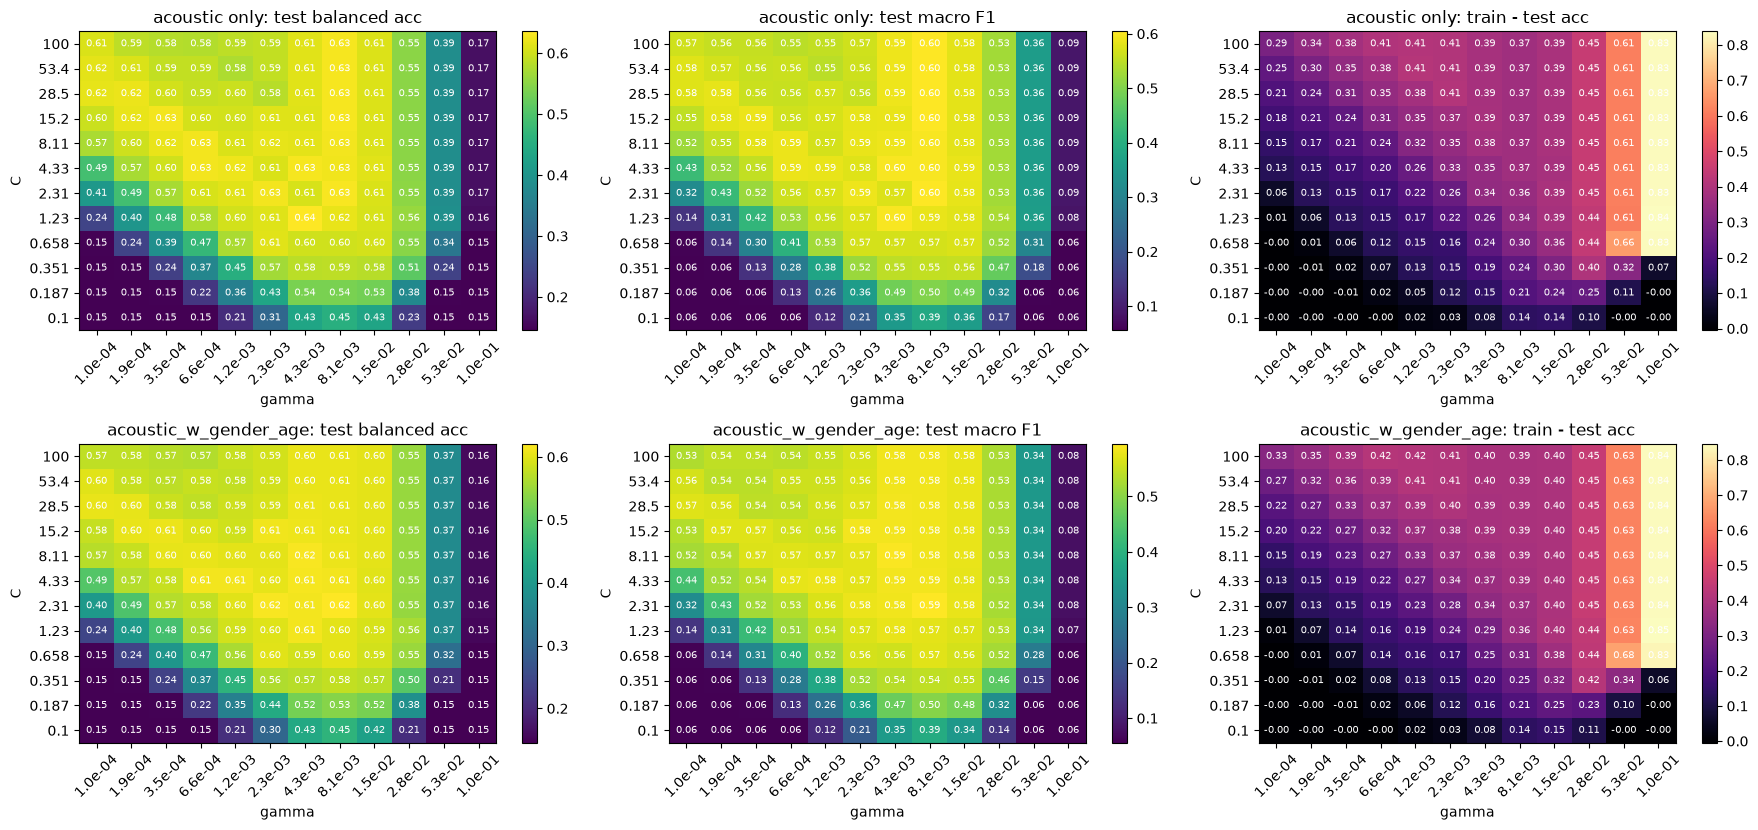

In [27]:
# with pca
all_rows = []
for C in Cs:
    for gamma in gammas:
        print(f"C={C:g}, gamma={gamma:g}")
        all_rows += train_model(model_w_PCA, C, gamma)
        
df_with_pca = pd.DataFrame(all_rows)

# one row per config: test acc, test F1, train-test gap
names = list(configs.keys())
fig, axes = plt.subplots(len(names), 3, figsize=(18, 4.2 * len(names)))
axes = np.atleast_2d(axes)
for r, name in enumerate(names):
    d = df_with_pca[df_with_pca["config"] == name].copy()
    d["gap_acc"] = d["train_balanced_acc"] - d["test_balanced_acc"]
    heatmap(axes[r, 0], d, "test_balanced_acc", f"{name}: test balanced acc")
    heatmap(axes[r, 1], d, "test_f1",  f"{name}: test macro F1")
    heatmap(axes[r, 2], d, "gap_acc",  f"{name}: train - test acc", cmap="magma")
plt.tight_layout(); plt.show()

C=0.1, gamma=0.0001
C=0.1, gamma=0.000187382
C=0.1, gamma=0.000351119
C=0.1, gamma=0.000657933
C=0.1, gamma=0.00123285
C=0.1, gamma=0.00231013
C=0.1, gamma=0.00432876
C=0.1, gamma=0.00811131
C=0.1, gamma=0.0151991
C=0.1, gamma=0.0284804
C=0.1, gamma=0.053367
C=0.1, gamma=0.1
C=0.187382, gamma=0.0001
C=0.187382, gamma=0.000187382
C=0.187382, gamma=0.000351119
C=0.187382, gamma=0.000657933
C=0.187382, gamma=0.00123285
C=0.187382, gamma=0.00231013
C=0.187382, gamma=0.00432876
C=0.187382, gamma=0.00811131
C=0.187382, gamma=0.0151991
C=0.187382, gamma=0.0284804
C=0.187382, gamma=0.053367
C=0.187382, gamma=0.1
C=0.351119, gamma=0.0001
C=0.351119, gamma=0.000187382
C=0.351119, gamma=0.000351119
C=0.351119, gamma=0.000657933
C=0.351119, gamma=0.00123285
C=0.351119, gamma=0.00231013
C=0.351119, gamma=0.00432876
C=0.351119, gamma=0.00811131
C=0.351119, gamma=0.0151991
C=0.351119, gamma=0.0284804
C=0.351119, gamma=0.053367
C=0.351119, gamma=0.1
C=0.657933, gamma=0.0001
C=0.657933, gamma=0.0001873

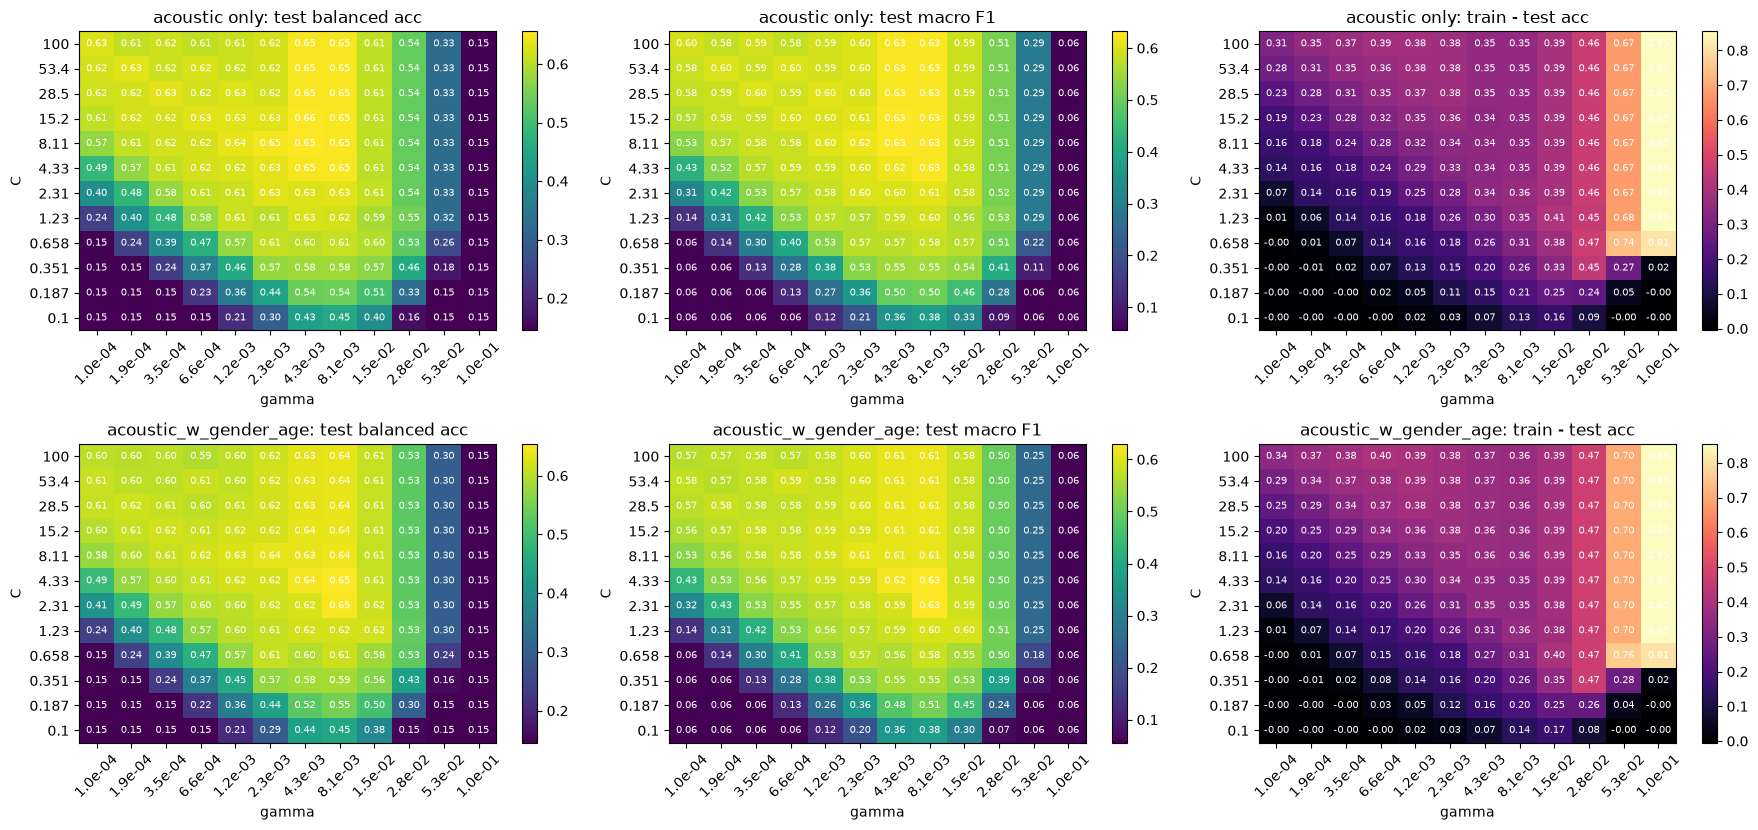

In [28]:
# without pca

all_rows = []
for C in Cs:
    for gamma in gammas:
        print(f"C={C:g}, gamma={gamma:g}")
        all_rows += train_model(model_wo_PCA, C, gamma)
        
df_without_pca = pd.DataFrame(all_rows)

# one row per config: test acc, test F1, train-test gap
names = list(configs.keys())
fig, axes = plt.subplots(len(names), 3, figsize=(18, 4.2 * len(names)))
axes = np.atleast_2d(axes)
for r, name in enumerate(names):
    d = df_without_pca[df_without_pca["config"] == name].copy()
    d["gap_acc"] = d["train_balanced_acc"] - d["test_balanced_acc"]
    heatmap(axes[r, 0], d, "test_balanced_acc", f"{name}: test balanced acc")
    heatmap(axes[r, 1], d, "test_f1",  f"{name}: test macro F1")
    heatmap(axes[r, 2], d, "gap_acc",  f"{name}: train - test acc", cmap="magma")
plt.tight_layout(); plt.show()